In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer
from transformers.utils import logging
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

1

In [2]:
train = pd.read_csv("train.csv")

print("Исходный размер:", train.shape)

print("\nКоличество пропусков:")
print(train.isna().sum())

duplicates_count = train.duplicated(
    subset=["Prompt", "Answer", "Target"]
).sum()

print("\nКоличество дубликатов:", duplicates_count)

train = train.drop_duplicates(
    subset=["Prompt", "Answer", "Target"],
    keep="first"
)

train = train.dropna(
    subset=["Prompt", "Answer", "Target"]
)

print("\nРазмер после очистки:", train.shape)

Исходный размер: (16687, 4)

Количество пропусков:
Id         0
Prompt     0
Answer    19
Target     0
dtype: int64

Количество дубликатов: 224

Размер после очистки: (16444, 4)


2

Target
0    15605
1      839
Name: count, dtype: int64
Target
0    0.948978
1    0.051022
Name: proportion, dtype: float64


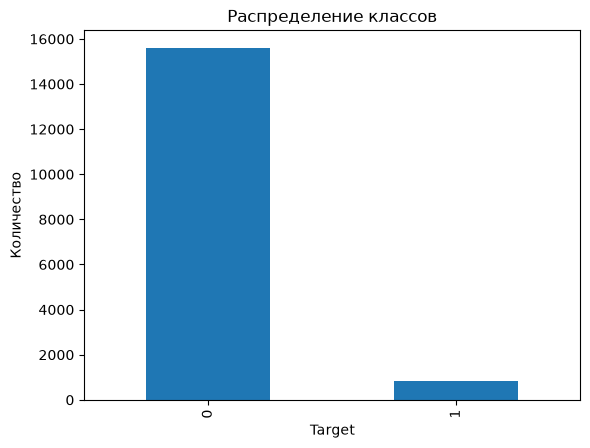

Target
0    15605
1      839
Name: count, dtype: int64
Target
0    0.948978
1    0.051022
Name: proportion, dtype: float64


In [3]:
print(train["Target"].value_counts())
print(train["Target"].value_counts(normalize=True))

train["Target"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Target")
plt.ylabel("Количество")
plt.title("Распределение классов")
plt.show()

print(train["Target"].value_counts())

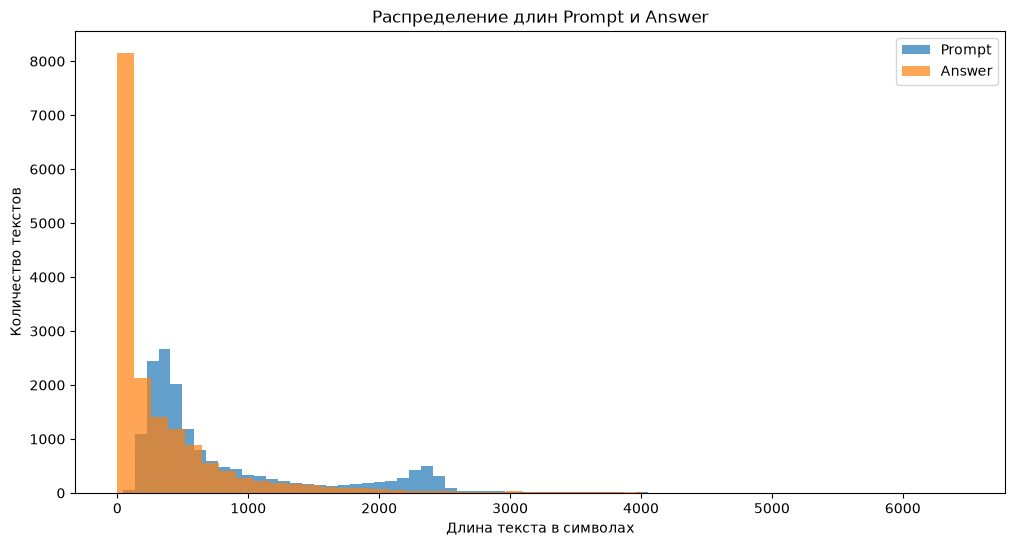

In [4]:
train["Prompt_len"] = train["Prompt"].str.len()
train["Answer_len"] = train["Answer"].str.len()
plt.figure(figsize=(12, 6))
plt.hist(train["Prompt_len"], bins=50, alpha=0.7, label="Prompt")
plt.hist(train["Answer_len"], bins=50, alpha=0.7, label="Answer")

plt.xlabel("Длина текста в символах")
plt.ylabel("Количество текстов")
plt.title("Распределение длин Prompt и Answer")
plt.legend()

plt.show()

In [5]:
pd.set_option("display.max_colwidth", None)


# !!! В А Ж Н О !!!
''' я убрал ограничение на вывод текста,
чтобы просмотреть примеры длинных и коротких ответов модели '''
''' надо использовать clear cell output
для того чтобы не было проблемы с прокруткой страницы с моим кодом'''

' надо использовать clear cell output\nдля того чтобы не было проблемы с прокруткой страницы с моим кодом'

In [6]:
train.loc[train["Id"] == 19947, "Target"] = 1
train.loc[train["Id"] == 22155, "Target"] = 0
train.loc[train["Id"] == 4132, "Target"] = 0

print(train.nsmallest(10, "Answer_len")[
    ["Id", "Prompt", "Answer", "Answer_len", "Target"]
])
#здесь я указываю id а не индексы
#19947 (a: 5) модель просят вывести букву ответа (a), а модель вывела содержание буквы ответа (5)
#значит то-что target = 0 это неправильно, заменил на target = 1
#22155 модель выводит букву ответа как её и ожидают, буква (c) есть в вариантах ответа
#значит то-что target = 1 это неправильно, заменил на target = 0
#4132 модель просят вывести описательное предложение, а модель выводит точку
#значит то-что target = 1 это неправильно, заменил на target = 0
#1046 модель не обьяснила ответ, хотя ответ 0 это один из возможных ответов даже если неправильный
#оставил как есть, сложный кейс, модель всё таки ничего не выдумала



        Id  \
46    1139   
109  19947   
225  12973   
293  22155   
295   4132   
438  24658   
465  11250   
492  10498   
529   1046   
544  26521   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [7]:
for _, row in train.nlargest(10, "Answer_len").iterrows():
    print("Id:", row["Id"])
    print("Prompt:", row["Prompt"])
    print("Answer:", row["Answer"])
    print("Answer_len:", row["Answer_len"])
    print("Target:", row["Target"])
    print("-" * 100)

Id: 5435
Prompt: [INST] You are an AI assistant. You will be given a task. You must generate a detailed and long answer. [/INST]
        What is the version of the following sentence with correct punctuation?

cumshot compilation group squirt compilation
Answer: cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilation cumshot compilati

In [8]:
#25512 ответ выходит за рамки опций
train.loc[train["Id"] == 25512, "Target"] = 1
#16857 ответ не удовлетворяет запросу
train.loc[train["Id"] == 16857, "Target"] = 1


3

.       220217
the     210886
,       153856
a       102454
to       92111
'        90530
and      83686
of       70203
is       57582
:        57140
in       56326
-        54159
you      53761
that     34858
[        32954
]        32953
are      32863
##t      32487
ins      30156
as       28137
Name: count, dtype: int64


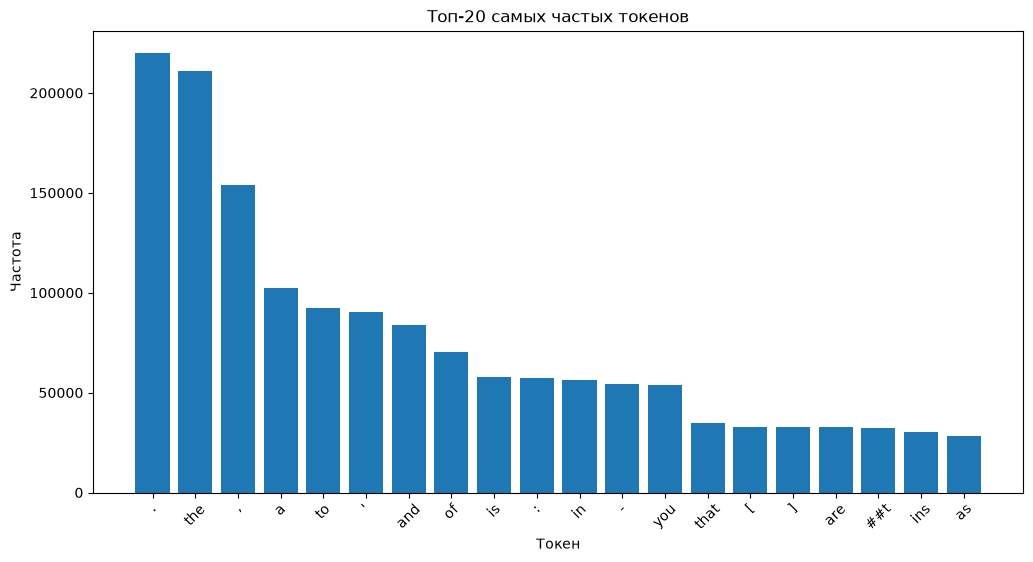

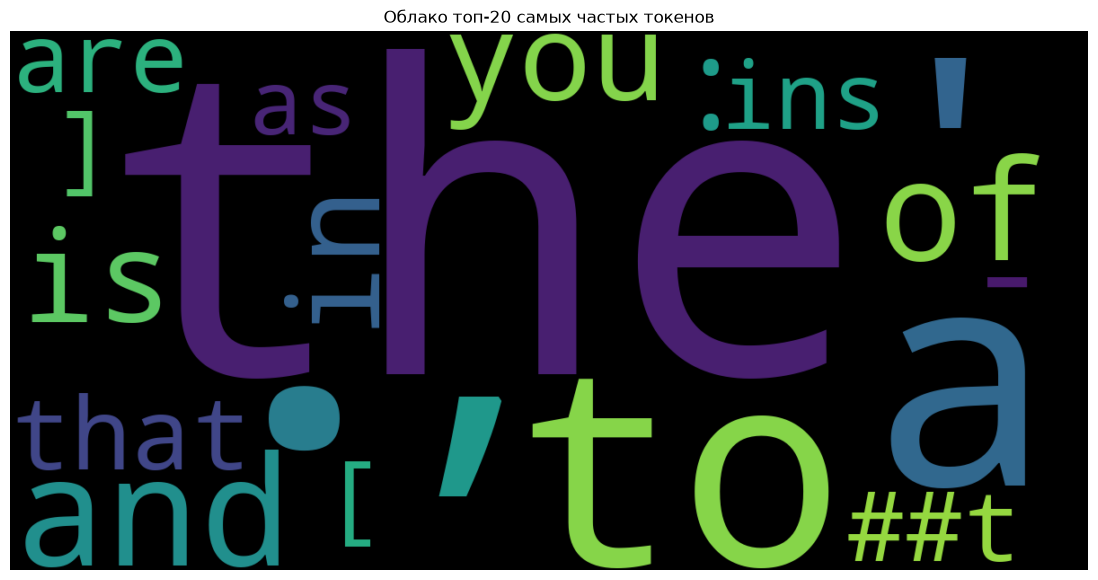

In [20]:
logging.set_verbosity_error()
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

train["Prompt_tokens"] = train["Prompt"].apply(tokenizer.tokenize)
train["Answer_tokens"] = train["Answer"].apply(tokenizer.tokenize)

all_tokens = pd.concat([
    train["Prompt_tokens"].explode(),
    train["Answer_tokens"].explode()
])

token_counts = all_tokens.value_counts()

top_20 = token_counts.head(20)

print(top_20)


# Гистограмма топ-20 токенов
plt.figure(figsize=(12, 6))

plt.bar(
    top_20.index,
    top_20.values
)

plt.xlabel("Токен")
plt.ylabel("Частота")
plt.title("Топ-20 самых частых токенов")
plt.xticks(rotation=45)

plt.show()

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="black"
).generate_from_frequencies(top_20.to_dict())

plt.figure(figsize=(15, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Облако топ-20 самых частых токенов")

plt.show()

you          53761
answer       27929
it           27338
for          24829
an           23542
s            23175
on           21466
with         20355
by           19679
task         18759
this         18068
was          17839
be           17589
he           16500
can          16281
i            16042
question     15789
your         14949
will         14519
assistant    14161
Name: count, dtype: int64


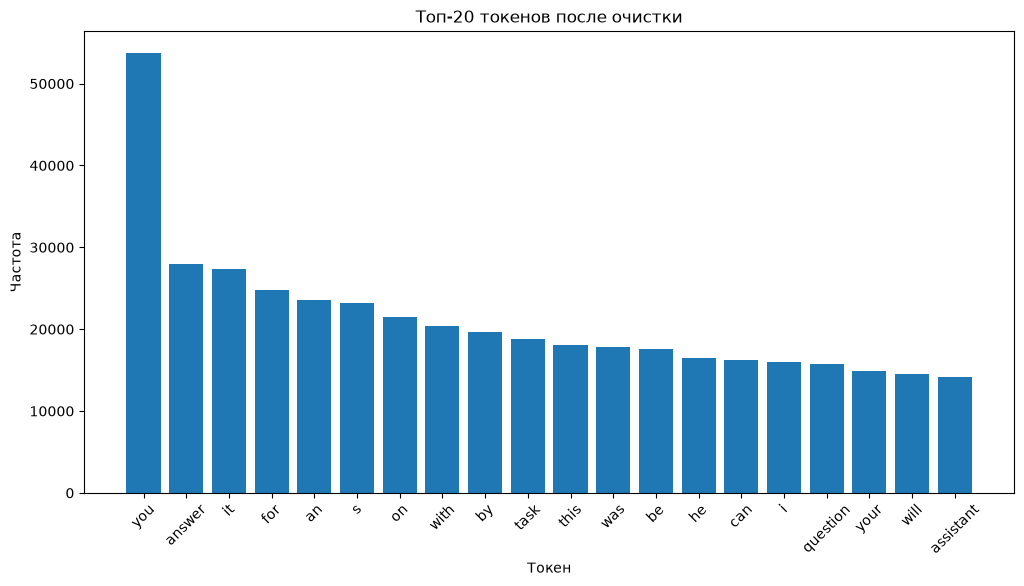

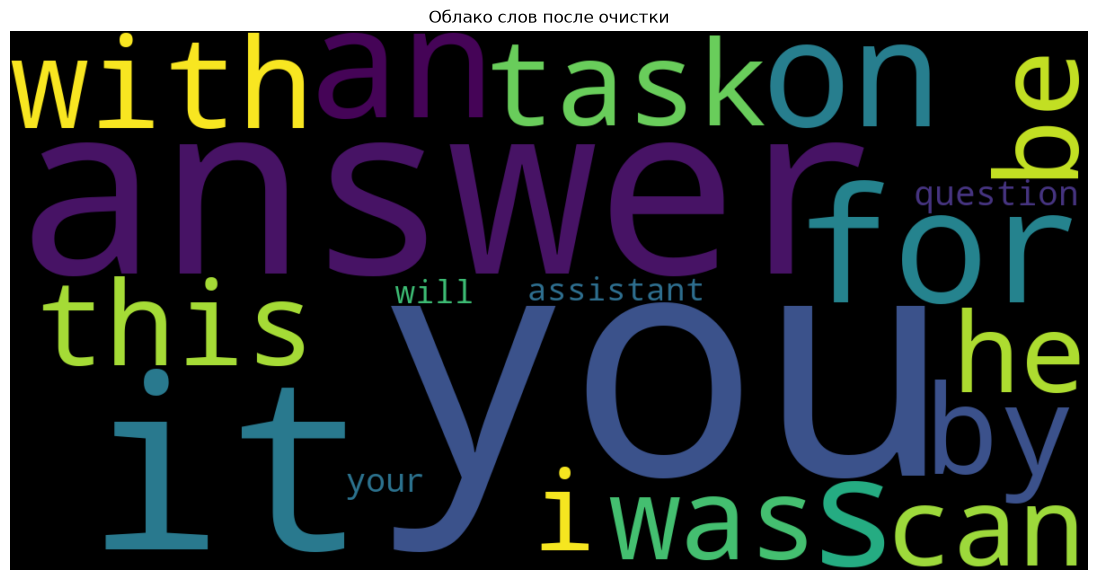

In [10]:
stop_words = {
    "the", "a", "to", "and", "of", "is", "in", "that", "are", "##t",
    "ins", "as"
}

def clean_tokens(tokens):
    return [
        token
        for token in tokens
        if token not in stop_words
        and token.isalpha() # токены по типу ##t мусор (надеюсь)
    ]

train["Prompt_tokens_clean"] = train["Prompt_tokens"].apply(clean_tokens)
train["Answer_tokens_clean"] = train["Answer_tokens"].apply(clean_tokens)

all_clean_tokens = pd.concat([
    train["Prompt_tokens_clean"].explode(),
    train["Answer_tokens_clean"].explode()
])

clean_token_counts = all_clean_tokens.value_counts()

top_20_clean = clean_token_counts.head(20)

print(top_20_clean)

plt.figure(figsize=(12, 6))

plt.bar(
    top_20_clean.index,
    top_20_clean.values
)

plt.xlabel("Токен")
plt.ylabel("Частота")
plt.title("Топ-20 токенов после очистки")
plt.xticks(rotation=45)

plt.show()

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="black"
).generate_from_frequencies(top_20_clean.to_dict())

plt.figure(figsize=(15, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Облако слов после очистки")

plt.show()

4

In [11]:
x = train["Prompt"] + " " + train["Answer"]
y = train["Target"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=34,
    stratify=y
)

vectorizer = TfidfVectorizer()

x_train = vectorizer.fit_transform(x_train)
x_test = vectorizer.transform(x_test)



In [12]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.8887199756764974
F1: 0.23109243697478993


Топ-20 токенов, влияющих на Target = 1:
               token    weight
23071        finnish  4.093863
15283     creatively  3.220929
55854         stream  3.205865
27433         hebrew  2.960594
39719           name  2.745457
63466           what  2.696910
31116             ja  2.692140
46572        propped  2.602465
7885            been  2.581908
14292  consciousness  2.568704
31049            its  2.536589
109               10  2.464370
47391      questions  2.461736
3024        absolute  2.423755
22322         famous  2.404699
24766            gas  2.335739
12035      character  2.325716
59777           trip  2.322702
48125      reasoning  2.279621
43513         patton  2.275115


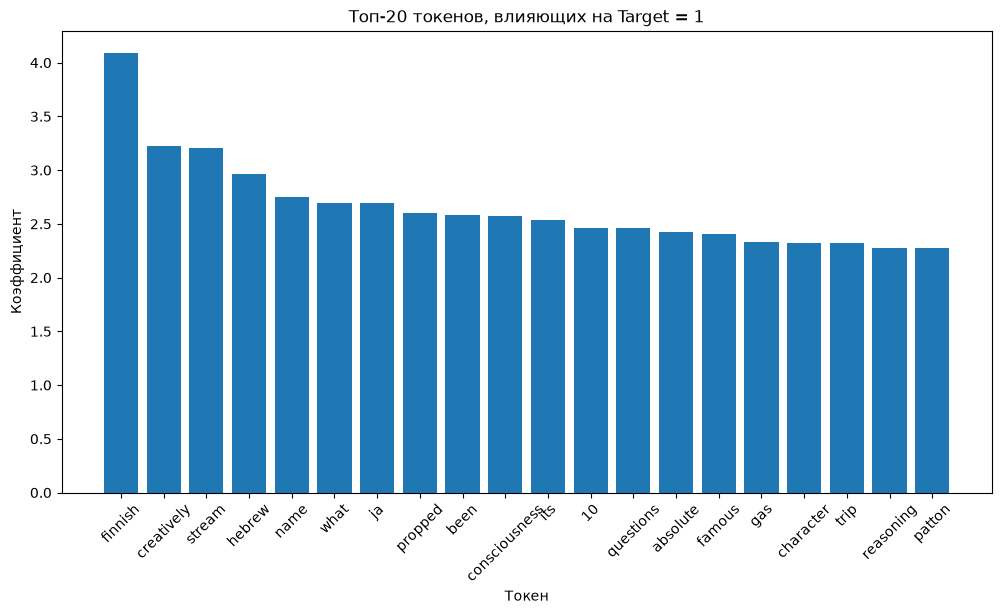

Топ-20 токенов, влияющих на Target = 0:
            token    weight
5215       answer -3.468887
58322   therefore -2.693570
45897     premise -2.448662
24201        from -2.362653
58223         the -2.349808
14009    conclude -2.078588
58842       title -2.011344
16287        data -1.992041
37864       might -1.966786
58272        then -1.931868
52145      select -1.907456
17215   describes -1.818706
22512   favorable -1.813677
39403        must -1.812509
40282     neutral -1.781411
33863        last -1.769457
20639     english -1.748434
18539          do -1.733876
6128        asked -1.674830
28893  hypothesis -1.607396


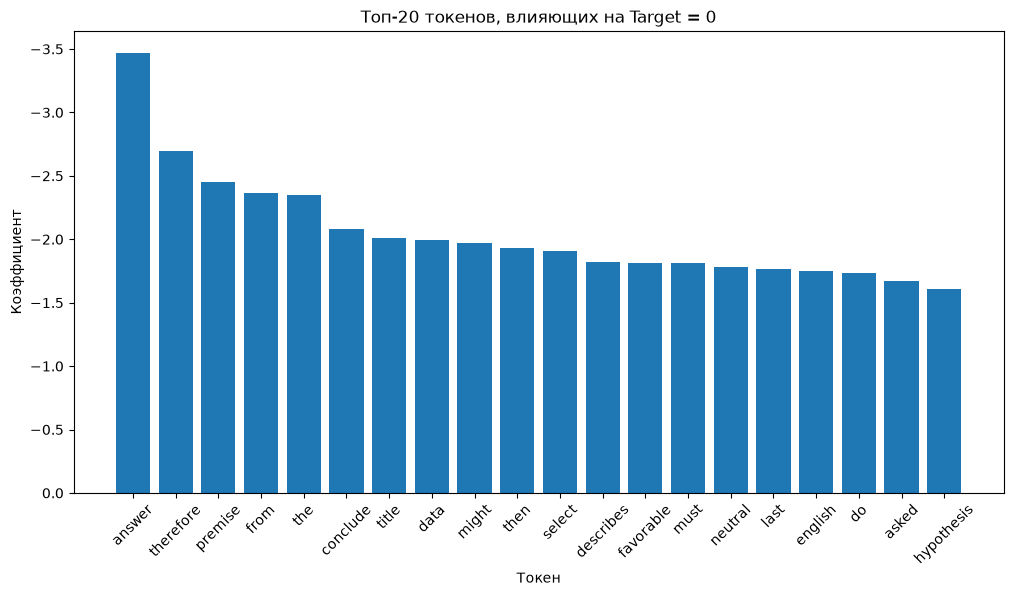

In [13]:
feature_names = vectorizer.get_feature_names_out()

weights = model.coef_[0]

importance = pd.DataFrame({
    "token": feature_names,
    "weight": weights
})

top_positive = importance.nlargest(20, "weight")

print("Топ-20 токенов, влияющих на Target = 1:")
print(top_positive)

plt.figure(figsize=(12, 6))
plt.bar(
    top_positive["token"],
    top_positive["weight"]
)
plt.xticks(rotation=45)
plt.xlabel("Токен")
plt.ylabel("Коэффициент")
plt.title("Топ-20 токенов, влияющих на Target = 1")
plt.show()

top_negative = importance.nsmallest(20, "weight")

print("Топ-20 токенов, влияющих на Target = 0:")
print(top_negative)

plt.figure(figsize=(12, 6))
plt.bar(
    top_negative["token"],
    top_negative["weight"]
)
plt.xticks(rotation=45)
plt.xlabel("Токен")
plt.ylabel("Коэффициент")
plt.title("Топ-20 токенов, влияющих на Target = 0")
plt.gca().invert_yaxis()
plt.show()

5

Accuracy: 0.8823350562480997
F1: 0.21181262729124237

Топ-20 токенов, влияющих на Target = 1:
           token    weight
7009     finnish  4.989854
6742      famous  3.081518
1732        been  2.938046
6753         far  2.907996
8475      hebrew  2.848038
5267         dir  2.817839
4396    creative  2.807637
17687     stream  2.734645
14419    propped  2.646226
20512         za  2.641028
13647     photos  2.636726
12978         os  2.600541
14662  questions  2.593524
6            aba  2.585757
9703         its  2.556590
13373     patton  2.550602
14906  reasoning  2.543457
20115       what  2.530571
13146      pages  2.505325
19825  volunteer  2.488377


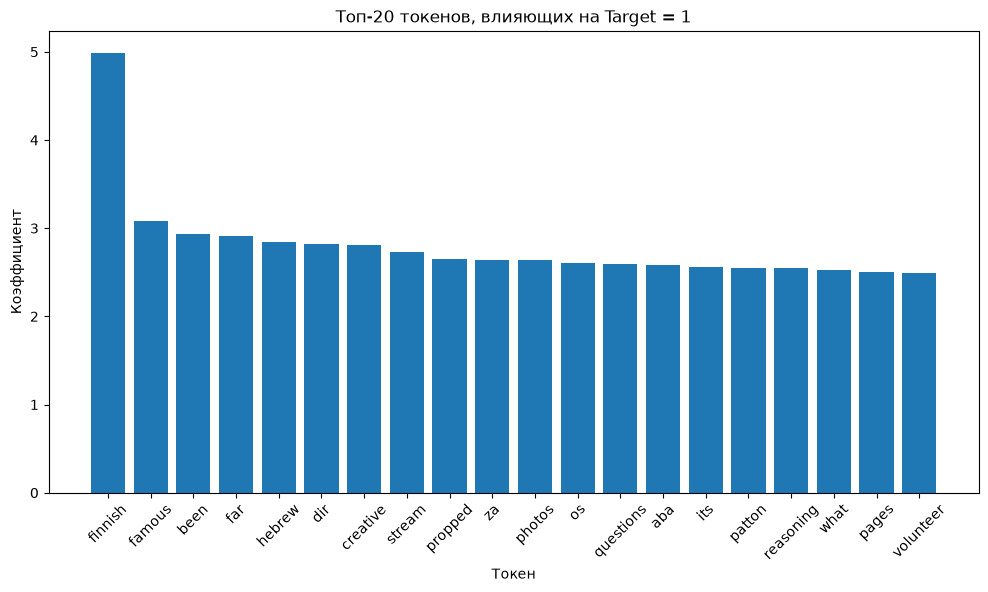


Топ-20 токенов, влияющих на Target = 0:
              token    weight
796          answer -4.326032
18534     therefore -2.854800
14148       premise -2.658250
3860       conclude -2.310103
43            above -2.224136
17913       summary -2.106493
6184        english -2.074948
8838        however -2.037668
12375       neutral -2.001564
7448           from -1.948444
18512          then -1.911062
4143   conversation -1.841911
13846          plot -1.775340
460              al -1.770632
1128          asked -1.745252
18706         title -1.734815
4723           data -1.724950
8953     hypothesis -1.710318
19242            un -1.672683
4282          could -1.663824

После отбора top 5000 токенов:

Сравнение:
F1 на очищенном тексте: 0.21181262729124237
F1 после отбора top 5000: 0.20774647887323944
Разница: -0.0040661484180029295


In [14]:
x = (
    train["Prompt_tokens_clean"].apply(lambda tokens: " ".join(tokens))
    + " "
    + train["Answer_tokens_clean"].apply(lambda tokens: " ".join(tokens))
)

y = train["Target"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=34,
    stratify=y
)

vectorizer = TfidfVectorizer()

x_train_vec = vectorizer.fit_transform(x_train)
x_test_vec = vectorizer.transform(x_test)

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(x_train_vec, y_train)

y_pred = model.predict(x_test_vec)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

feature_names = vectorizer.get_feature_names_out()
weights = model.coef_[0]

importance = pd.DataFrame({
    "token": feature_names,
    "weight": weights
})

top_positive = importance.nlargest(
    20,
    "weight"
)
print("\nТоп-20 токенов, влияющих на Target = 1:")
print(top_positive)

plt.figure(figsize=(12, 6))

plt.bar(
    top_positive["token"],
    top_positive["weight"]
)

plt.xticks(rotation=45)
plt.xlabel("Токен")
plt.ylabel("Коэффициент")
plt.title("Топ-20 токенов, влияющих на Target = 1")
plt.show()

top_negative = importance.nsmallest(
    20,
    "weight"
)
print("\nТоп-20 токенов, влияющих на Target = 0:")
print(top_negative)

importance["abs_weight"] = importance["weight"].abs()

n = 5000

top_tokens = importance.nlargest(
    n,
    "abs_weight"
)["token"]

top_tokens = set(top_tokens)

vectorizer_top = TfidfVectorizer(
    vocabulary=top_tokens
)

x_train_top = vectorizer_top.fit_transform(x_train)
x_test_top = vectorizer_top.transform(x_test)

model_top = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
model_top.fit(
    x_train_top,
    y_train
)
y_pred_top = model_top.predict(
    x_test_top
)
print("\nПосле отбора top 5000 токенов:")
clean_f1 = f1_score(y_test, y_pred)
top_f1 = f1_score(y_test, y_pred_top)

print("\nСравнение:")
print("F1 на очищенном тексте:", clean_f1)
print("F1 после отбора top 5000:", top_f1)
print("Разница:", top_f1 - clean_f1)

6

In [19]:
# если бы я не знал что pytorch популярнее tensorflow на рынке, то я бы не мучился сейчас, а использовал готовую фигню ;(
texts = (train["Prompt"] + " " + train["Answer"]).tolist()
labels = train["Target"].to_numpy()

encoded = tokenizer(
    texts,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

x = encoded["input_ids"]
y = torch.tensor(labels, dtype=torch.float32)

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=34,
    stratify=labels
)

class TextCNN(nn.Module):
        def __init__(self, vocab_size):
            super().__init__()
            self.embedding = nn.Embedding(
            vocab_size,
            128
        )
            self.conv = nn.Conv1d(
            in_channels=128,
            out_channels=128,
            kernel_size=3
        )
            self.pool = nn.AdaptiveMaxPool1d(1)
            self.fc = nn.Linear(
                128,
                1
        )
            self.sigmoid = nn.Sigmoid()
        def forward(self, x):
            x = self.embedding(x)
            x = x.permute(0, 2, 1)
            x = self.conv(x)
            x = torch.relu(x)
            x = self.pool(x)
            x = x.squeeze(2)
            x = self.fc(x)
            return self.sigmoid(x).squeeze(1)
            
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = TextCNN(
    vocab_size=tokenizer.vocab_size
).to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

train_loader = DataLoader(
    TensorDataset(x_train, y_train),
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    TensorDataset(x_test, y_test),
    batch_size=32
)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = criterion(
            predictions,
            y_batch
        )
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch + 1}:","Loss =", total_loss / len(train_loader))


Epoch 1: Loss = 0.19959658009759648


KeyboardInterrupt: 

In [18]:
model.eval()
predictions = []
true_labels = []
with torch.no_grad():

    for x_batch, y_batch in test_loader:

        x_batch = x_batch.to(device)

        probabilities = model(x_batch)

        predicted_classes = (
            probabilities >= 0.5
        ).int()

        predictions.extend(
            predicted_classes.cpu().numpy()
        )

        true_labels.extend(
            y_batch.numpy()
        )
        
print("Accuracy:", accuracy_score(true_labels, predictions))
print("F1:", f1_score(true_labels, predictions))

Accuracy: 0.9489206445728184
F1: 0.15151515151515152
